Classes=33, train=19734, val=4224, test=4224
Epoch 1/3 | loss=2.1149 acc=0.4111 | val_loss=1.3431 val_acc=0.5902 | 13.8s
Epoch 2/3 | loss=0.9898 acc=0.6993 | val_loss=0.7744 val_acc=0.7682 | 16.1s
Epoch 3/3 | loss=0.6148 acc=0.8117 | val_loss=0.5185 val_acc=0.8286 | 14.5s
Test : loss=0.5159, accuracy=0.8362


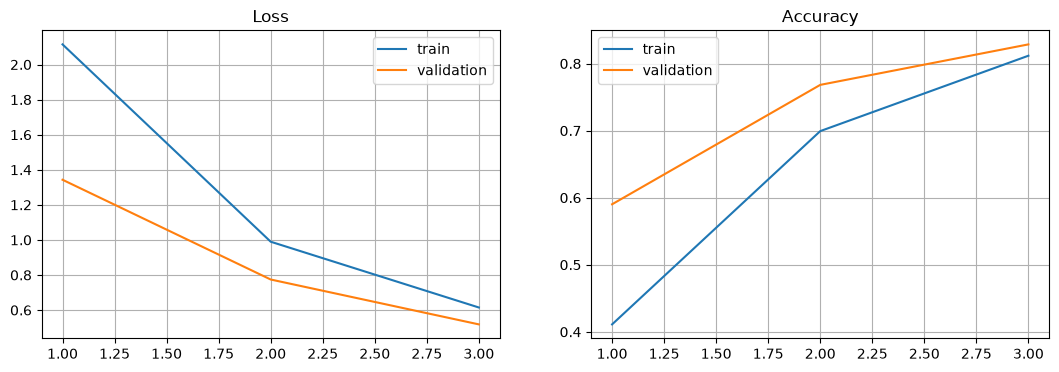

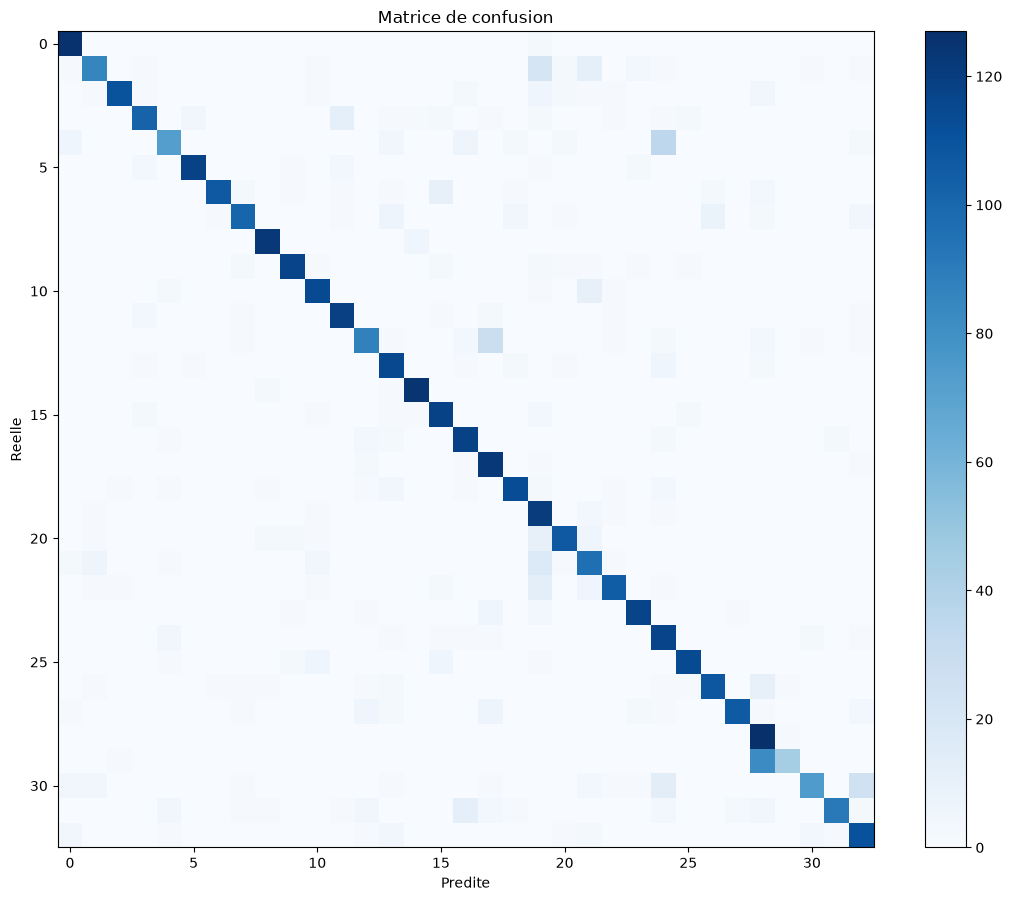

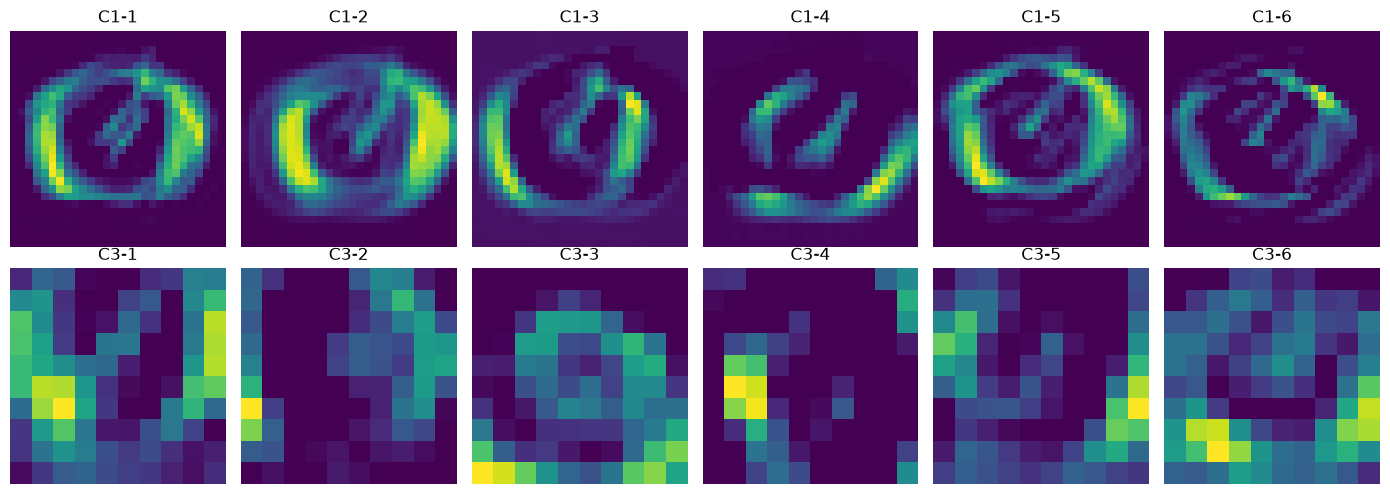

In [4]:
# TP LeNet-5 Tifinagh - implementation from scratch avec NumPy
# Version acceleree : mini-batches, sliding_window_view et operations vectorisees
# Dependances : numpy, matplotlib, pillow

import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ========================= PARAMETRES =========================
SEED = 42
np.random.seed(SEED)
datebase_tifinagh = Path("data")
IMG_SIZE = (32, 32)
NB_CLASSES_ATTENDU = 33
EPOCHS = 3                 # commencer par 1 ou 3 ; augmenter ensuite
BATCH_SIZE = 128           # 64 si la memoire est limitee
LEARNING_RATE = 0.001
OPTIMIZER = "adam"         # "adam" ou "sgd"
MOMENTUM = 0.9
QUICK_TEST = False          # True = utilise un petit sous-ensemble pour verifier le code
MAX_TRAIN = 1000            # utilise seulement si QUICK_TEST=True
MAX_VAL = 200
MAX_TEST = 200

datebase_tifinagh = Path("tifinagh-images")

# ========================= DONNEES =========================
EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
if not datebase_tifinagh.exists():
    raise FileNotFoundError(f"Dossier introuvable : {datebase_tifinagh.resolve()}")

class_names = sorted([p.name for p in datebase_tifinagh.iterdir() if p.is_dir()])
if not class_names:
    raise ValueError("Aucun dossier de classe dans data/")
class_to_id = {name: i for i, name in enumerate(class_names)}
paths, labels = [], []
for name in class_names:
    for p in sorted((datebase_tifinagh / name).rglob("*")):
        if p.is_file() and p.suffix.lower() in EXTENSIONS:
            paths.append(str(p)); labels.append(class_to_id[name])
paths, labels = np.array(paths), np.array(labels, dtype=np.int64)
if len(paths) == 0:
    raise ValueError("Aucune image trouvee.")

def load_image(path):
    im = Image.open(path).convert("L").resize(IMG_SIZE)
    return np.asarray(im, dtype=np.float32)[None, :, :] / 255.0

X = np.stack([load_image(p) for p in paths]).astype(np.float32)
y = labels
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for c in range(len(class_names)):
    idx = np.where(y == c)[0]; rng.shuffle(idx)
    nt = max(1, int(.15 * len(idx))); nv = max(1, int(.15 * len(idx)))
    test_idx.extend(idx[:nt]); val_idx.extend(idx[nt:nt+nv]); train_idx.extend(idx[nt+nv:])
rng.shuffle(train_idx); rng.shuffle(val_idx); rng.shuffle(test_idx)
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
if QUICK_TEST:
    X_train, y_train = X_train[:MAX_TRAIN], y_train[:MAX_TRAIN]
    X_val, y_val = X_val[:MAX_VAL], y_val[:MAX_VAL]
    X_test, y_test = X_test[:MAX_TEST], y_test[:MAX_TEST]
print(f"Classes={len(class_names)}, train={len(y_train)}, val={len(y_val)}, test={len(y_test)}")
if len(class_names) != NB_CLASSES_ATTENDU:
    print(f"Attention : {len(class_names)} classes detectees, 33 attendues.")

# ========================= COUCHES NUMPY =========================
def relu(x): return np.maximum(x, 0)
def drelu(x): return (x > 0).astype(np.float32)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    ez = np.exp(z)
    return ez / ez.sum(axis=1, keepdims=True)

def cross_entropy(p, y):
    return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()

def im2col(x, k=5, stride=1, padding=0):
    if padding:
        x = np.pad(x, ((0,0),(0,0),(padding,padding),(padding,padding)))
    # fenetres : N,C,Hout,Wout,k,k ; aucun parcours Python sur les pixels
    windows = np.lib.stride_tricks.sliding_window_view(x, (k, k), axis=(2,3))
    windows = windows[:, :, ::stride, ::stride, :, :]
    n, c, ho, wo, _, _ = windows.shape
    return windows.transpose(0,2,3,1,4,5).reshape(n*ho*wo, -1), (n, c, ho, wo)

def conv_forward(x, w, b, k=5):
    cols, shape = im2col(x, k)
    out = cols @ w.reshape(w.shape[0], -1).T + b
    n, c, ho, wo = shape
    return out.reshape(n, ho, wo, w.shape[0]).transpose(0,3,1,2), (x, cols, shape, w)

def conv_backward(dout, cache):
    x, cols, (n, c, ho, wo), w = cache
    f, _, k, _ = w.shape
    dout2 = dout.transpose(0,2,3,1).reshape(-1, f)
    dw = (dout2.T @ cols).reshape(w.shape)
    db = dout2.sum(axis=0)
    dcols = (dout2 @ w.reshape(f, -1)).reshape(n, ho, wo, c, k, k)
    dx = np.zeros_like(x)
    # seulement 25 iterations sur les positions du filtre, pas sur les images
    for i in range(k):
        for j in range(k):
            dx[:, :, i:i+ho, j:j+wo] += dcols[:, :, :, :, i, j].transpose(0,3,1,2)
    return dx, dw, db

def pool_forward(x):
    n,c,h,w = x.shape
    out = x.reshape(n,c,h//2,2,w//2,2).mean(axis=(3,5))
    return out, x

def pool_backward(dout, cache):
    return np.repeat(np.repeat(dout, 2, axis=2), 2, axis=3) / 4.0

# ========================= LENET-5 =========================
class LeNet5:
    def __init__(self, classes, seed=42):
        r = np.random.default_rng(seed)
        self.W1 = r.normal(0, np.sqrt(2/25), (6,1,5,5)).astype(np.float32); self.b1=np.zeros(6,np.float32)
        self.W2 = r.normal(0, np.sqrt(2/150), (16,6,5,5)).astype(np.float32); self.b2=np.zeros(16,np.float32)
        self.W3 = r.normal(0, np.sqrt(2/400), (400,120)).astype(np.float32); self.b3=np.zeros(120,np.float32)
        self.W4 = r.normal(0, np.sqrt(2/120), (120,84)).astype(np.float32); self.b4=np.zeros(84,np.float32)
        self.W5 = r.normal(0, np.sqrt(2/84), (84,classes)).astype(np.float32); self.b5=np.zeros(classes,np.float32)
        self.params = {k:getattr(self,k) for k in ["W1","b1","W2","b2","W3","b3","W4","b4","W5","b5"]}
        self.grads = {}
    def forward(self, x, save=True):
        z1,c1=conv_forward(x,self.W1,self.b1); a1=relu(z1); s2,p2=pool_forward(a1)
        z2,c2=conv_forward(s2,self.W2,self.b2); a2=relu(z2); s4,p4=pool_forward(a2)
        flat=s4.reshape(len(x),-1); z3=flat@self.W3+self.b3; a3=relu(z3)
        z4=a3@self.W4+self.b4; a4=relu(z4); logits=a4@self.W5+self.b5; prob=softmax(logits)
        if save: self.cache=(x,z1,a1,s2,z2,a2,s4,flat,z3,a3,z4,a4,prob,c1,p2,c2,p4)
        return prob
    def backward(self, y):
        x,z1,a1,s2,z2,a2,s4,flat,z3,a3,z4,a4,p,c1,p2,c2,p4=self.cache
        n=len(y); dz5=p.copy(); dz5[np.arange(n),y]-=1; dz5/=n
        dW5=a4.T@dz5; db5=dz5.sum(0); da4=dz5@self.W5.T; dz4=da4*drelu(z4)
        dW4=a3.T@dz4; db4=dz4.sum(0); da3=dz4@self.W4.T; dz3=da3*drelu(z3)
        dW3=flat.T@dz3; db3=dz3.sum(0); ds4=(dz3@self.W3.T).reshape(s4.shape)
        da2=pool_backward(ds4,p4); dz2=da2*drelu(z2); ds2,dW2,db2=conv_backward(dz2,c2)
        da1=pool_backward(ds2,p2); dz1=da1*drelu(z1); _,dW1,db1=conv_backward(dz1,c1)
        self.grads={"W1":dW1,"b1":db1,"W2":dW2,"b2":db2,"W3":dW3,"b3":db3,"W4":dW4,"b4":db4,"W5":dW5,"b5":db5}

# ========================= OPTIMISEURS =========================
class Adam:
    def __init__(self, lr=.001): self.lr=lr; self.t=0; self.m={}; self.v={}
    def step(self, model):
        self.t += 1
        for k,p in model.params.items():
            g=model.grads[k]; self.m[k]=.9*self.m.get(k,0)+.1*g; self.v[k]=.999*self.v.get(k,0)+.001*g*g
            mh=self.m[k]/(1-.9**self.t); vh=self.v[k]/(1-.999**self.t); p -= self.lr*mh/(np.sqrt(vh)+1e-8)
class SGD:
    def __init__(self, lr=.01, momentum=.9): self.lr=lr; self.mu=momentum; self.v={}
    def step(self, model):
        for k,p in model.params.items(): self.v[k]=self.mu*self.v.get(k,0)-self.lr*model.grads[k]; p += self.v[k]

# ========================= TRAIN / VALIDATION / TEST =========================
def evaluate(model, X_, y_, batch=128):
    losses=[]; preds=[]
    for start in range(0,len(y_),batch):
        p=model.forward(X_[start:start+batch], save=False); yy=y_[start:start+batch]
        losses.append(cross_entropy(p,yy)*len(yy)); preds.extend(np.argmax(p,1))
    preds=np.array(preds); return sum(losses)/len(y_), np.mean(preds==y_), preds

def train(model, opt, epochs, batch=128):
    hist={"loss":[],"accuracy":[],"val_loss":[],"val_accuracy":[]}; rng=np.random.default_rng(SEED)
    for ep in range(epochs):
        t=time.time(); idx=np.arange(len(y_train)); rng.shuffle(idx); loss_sum=0; correct=0
        for start in range(0,len(idx),batch):
            ii=idx[start:start+batch]; p=model.forward(X_train[ii]); yy=y_train[ii]
            loss_sum += cross_entropy(p,yy)*len(yy); correct += np.sum(np.argmax(p,1)==yy)
            model.backward(yy); opt.step(model)
        vl,va,_=evaluate(model,X_val,y_val,batch); l=loss_sum/len(y_train); a=correct/len(y_train)
        hist["loss"].append(l); hist["accuracy"].append(a); hist["val_loss"].append(vl); hist["val_accuracy"].append(va)
        print(f"Epoch {ep+1}/{epochs} | loss={l:.4f} acc={a:.4f} | val_loss={vl:.4f} val_acc={va:.4f} | {time.time()-t:.1f}s")
    return hist

# ========================= EXECUTION =========================
model = LeNet5(len(class_names), SEED)
optimizer = Adam(LEARNING_RATE) if OPTIMIZER.lower()=="adam" else SGD(LEARNING_RATE, MOMENTUM)
history = train(model, optimizer, EPOCHS, BATCH_SIZE)
test_loss, test_acc, y_pred = evaluate(model, X_test, y_test, BATCH_SIZE)
print(f"Test : loss={test_loss:.4f}, accuracy={test_acc:.4f}")

# Courbes
xep=range(1,EPOCHS+1); fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].plot(xep,history["loss"],label="train"); ax[0].plot(xep,history["val_loss"],label="validation"); ax[0].set_title("Loss"); ax[0].legend(); ax[0].grid()
ax[1].plot(xep,history["accuracy"],label="train"); ax[1].plot(xep,history["val_accuracy"],label="validation"); ax[1].set_title("Accuracy"); ax[1].legend(); ax[1].grid(); plt.show()

# Matrice de confusion NumPy
cm=np.zeros((len(class_names),len(class_names)),dtype=int); np.add.at(cm,(y_test,y_pred),1)
plt.figure(figsize=(11,9)); plt.imshow(cm,cmap="Blues"); plt.colorbar(); plt.title("Matrice de confusion"); plt.xlabel("Predite"); plt.ylabel("Reelle"); plt.tight_layout(); plt.show()

# Cartes C1 et C3
z1,_=conv_forward(X_test[:1],model.W1,model.b1); a1=relu(z1); s2,_=pool_forward(a1); z2,_=conv_forward(s2,model.W2,model.b2); a2=relu(z2)
fig,ax=plt.subplots(2,6,figsize=(14,5))
for i in range(6):
    ax[0,i].imshow(a1[0,i],cmap="viridis"); ax[0,i].set_title(f"C1-{i+1}"); ax[0,i].axis("off")
    ax[1,i].imshow(a2[0,i],cmap="viridis"); ax[1,i].set_title(f"C3-{i+1}"); ax[1,i].axis("off")
plt.tight_layout(); plt.show()
